In [1]:
# Basic Libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import pydot

# Machine Learning
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV

# Deep Learning
import tensorflow as tf
import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout,Input
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# SciKeras Wrapper
from scikeras.wrappers import KerasClassifier

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [3]:
x_train.shape

(60000, 28, 28)

In [4]:
x_test.shape

(10000, 28, 28)

In [5]:
y_train.shape

(60000,)

In [6]:
y_test.shape

(10000,)

In [7]:
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)
input_shape = (28, 28, 1)

In [8]:
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

dtype = data type
float32 = 32-bit floating-point number

Neural networks usually use float32 because:

it stores decimal values,
it uses less memory than float64,
and computations are faster on CPUs and GPUs.

In [9]:
x_test

array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
 

In [10]:
x_test[1]

array([[[  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.]],

       [[  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.]],

       [[  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
        [  0.],
    

In [11]:
x_train /= 255
x_test /= 255

x_train /= 255 and x_test /= 255 normalize the image pixel values from the range 0–255 to 0–1 by dividing every pixel by 255.
This preprocessing step helps the CNN train faster, improves numerical stability, and often leads to better model performance 
because the inputs are on a consistent scale.

Better accuracy
Large input values can make the optimization process unstable.
Normalized data usually helps the model find better weights, often leading to higher accuracy.

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Dropout, Flatten, MaxPooling2D
model = Sequential()
model.add(Conv2D(28, kernel_size=(3,3), input_shape=input_shape))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(128, activation=tf.nn.relu))
model.add(Dropout(0.2))
model.add(Dense(10,activation=tf.nn.softmax))

C:\Users\Admin\anaconda3\envs\aiml1\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
#https://keras.io/api/optimizers/
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

1)Adam optimization is a stochastic gradient descent method that is based on adaptive estimation of first-order and second-order moments.
The method is "computationally efficient, has little memory requirement, invariant to diagonal rescaling of gradients, and is well suited for problems that are large in terms of data/parameters".

2)Use this crossentropy loss function when there are two or more label classes. We expect labels to be provided as integers. If you want to provide labels using one-hot representation, please use CategoricalCrossentropy loss. There should be # classes floating point values per feature for y_pred and a single floating point value per feature for y_true.

3)Calculates how often predictions equal labels.

This metric creates two local variables, total and count that are used to compute the frequency with which y_pred matches y_true. This frequency is ultimately returned as binary accuracy: an idempotent operation that simply divides total by count.

In [14]:
history=model.fit(x_train, y_train, batch_size=100, epochs=10,validation_data=(x_test, y_test))

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.9225 - loss: 0.2635 - val_accuracy: 0.9691 - val_loss: 0.1029
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.9688 - loss: 0.1039 - val_accuracy: 0.9778 - val_loss: 0.0712
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9785 - loss: 0.0706 - val_accuracy: 0.9813 - val_loss: 0.0581
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9827 - loss: 0.0536 - val_accuracy: 0.9821 - val_loss: 0.0555
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9863 - loss: 0.0428 - val_accuracy: 0.9829 - val_loss: 0.0553
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9892 - loss: 0.0342 - val_accuracy: 0.9840 - val_loss: 0.0518
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9908 - loss: 0.0296 - val_accuracy: 0.9864 - val_loss: 0.0467
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9919 - loss: 0.0236 - 

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 28)          │             280 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 28)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4732)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         605,824 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,822,184 (6.95 MB)

 Trainable params: 607,394 (2.32 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,214,790 (4.63 MB)

In [16]:
model.evaluate(x_test, y_test)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9857 - loss: 0.0480


[0.04799453914165497, 0.9857000112533569]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
9


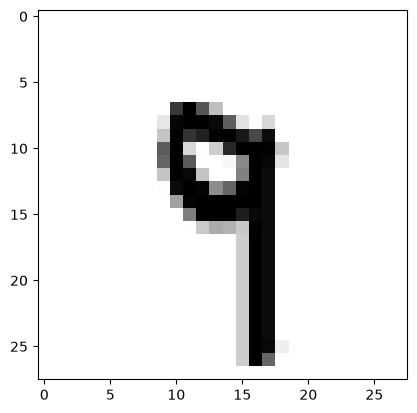

In [17]:
import matplotlib.pyplot as plt
image_index = 6910
plt.imshow(x_test[image_index].reshape(28, 28),cmap='Greys')
predict = x_test[image_index].reshape(28,28)
pred = model.predict(x_test[image_index].reshape(1, 28, 28, 1))
print(pred.argmax())

First, I select one image from the test dataset and display it. Then I reshape the image to (1, 28, 28, 1) because the CNN expects input in the format (batch_size, height, width, channels). The model outputs probabilities for all ten digit classes, and argmax() returns the index with the highest probability, which is the predicted digit."

In [18]:
y_predict = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


test dataset contains 10,000 images.
By default, Keras uses a batch size of 32 during prediction.
32/10000=312.5
Since the last batch contains the remaining images, Keras creates 313 batches.

In [19]:
y_predict

array([[3.2295590e-12, 4.1481216e-10, 9.4208099e-09, ..., 9.9999988e-01,
        6.7651104e-13, 3.5906947e-10],
       [2.9488754e-07, 4.6085956e-06, 9.9999511e-01, ..., 1.0213306e-14,
        5.5316285e-12, 5.4232290e-16],
       [1.6424649e-09, 9.9999452e-01, 8.2772402e-07, ..., 3.6858762e-06,
        7.8031445e-07, 1.7797191e-09],
       ...,
       [1.5978347e-18, 1.6896389e-12, 9.6153976e-17, ..., 1.2251528e-08,
        3.0878037e-12, 5.7060165e-09],
       [5.0389983e-12, 1.1536053e-11, 4.8529423e-15, ..., 5.9744043e-11,
        4.7839817e-06, 5.3463402e-14],
       [1.4189622e-08, 4.8427665e-11, 4.3871373e-09, ..., 9.3530727e-14,
        1.7732418e-11, 2.7203592e-13]], shape=(10000, 10), dtype=float32)

In [20]:
print(y_predict.dtype)

float32


In [21]:
y_predict[0]

array([3.2295590e-12, 4.1481216e-10, 9.4208099e-09, 1.2123162e-07,
       7.9263133e-12, 3.6522551e-12, 3.5479439e-16, 9.9999988e-01,
       6.7651104e-13, 3.5906947e-10], dtype=float32)

It is a 1-dimensional NumPy array with 10 elements, one probability for each digit (0–9).

"The model output is a NumPy array of type float32 containing 10 softmax probabilities, one for each digit class (0–9). The index with the highest probability, obtained using np.argmax(), is the predicted digit."

In [25]:
y_predict = np.argmax(y_predict, axis=1)

It is a 1-dimensional NumPy array containing integer class labels.
axis=1 means move across each row (left to right).For each image, find the column with the largest probability.
Axis	Direction	Used for
axis=0	Top → Bottom	Find the maximum in each column
axis=1	Left → Right	Find the maximum in each row (used in classification)

np.argmax(y_predict, axis=1) returns the index of the maximum value across each row. In a classification model, each row contains the predicted probabilities for one image across all classes. axis=1 selects the class with the highest probability for every image, converting probability vectors into predicted class labels such as 0, 1, ..., 9.

In [22]:
print(y_test.shape)
print(y_test[:5])

(10000,)
[7 2 1 0 4]


In [23]:
y_test

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,), dtype=uint8)

In [26]:
y_predict

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

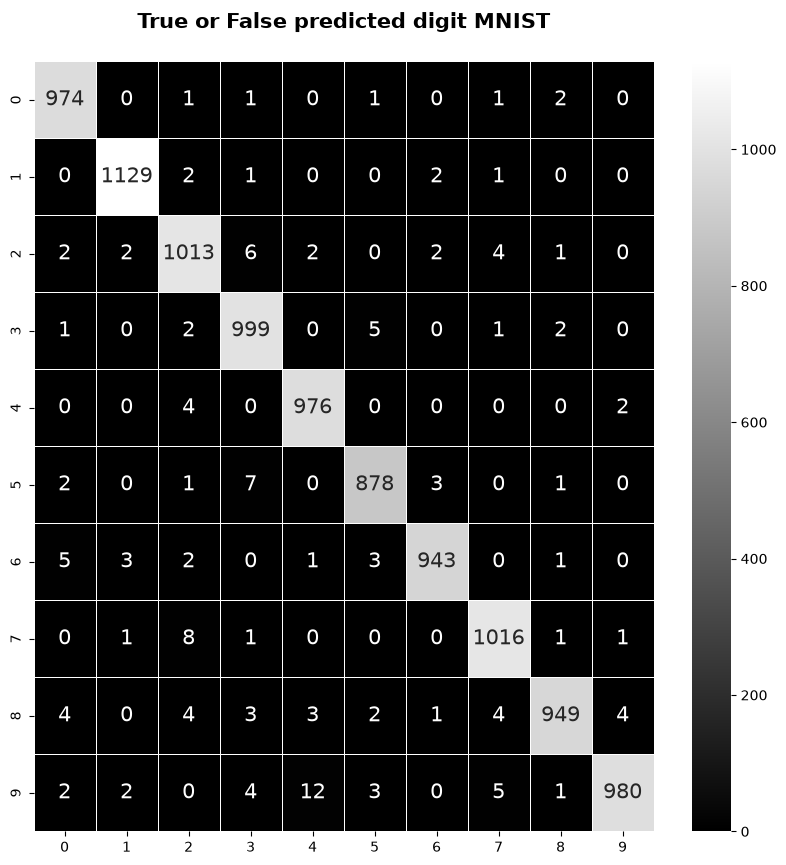

In [27]:
con_mat=confusion_matrix(y_test,y_predict)
plt.style.use('seaborn-v0_8-deep')
plt.figure(figsize=(10,10))
sns.heatmap(con_mat,annot=True,annot_kws={'size':15},linewidths=0.5,fmt='d',cmap='gray')
plt.title('True or False predicted digit MNIST\n',fontweight='bold',fontsize=15)
plt.show()           


In [28]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.98      0.99      0.98      1010
           4       0.98      0.99      0.99       982
           5       0.98      0.98      0.98       892
           6       0.99      0.98      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.99      0.97      0.98       974
           9       0.99      0.97      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



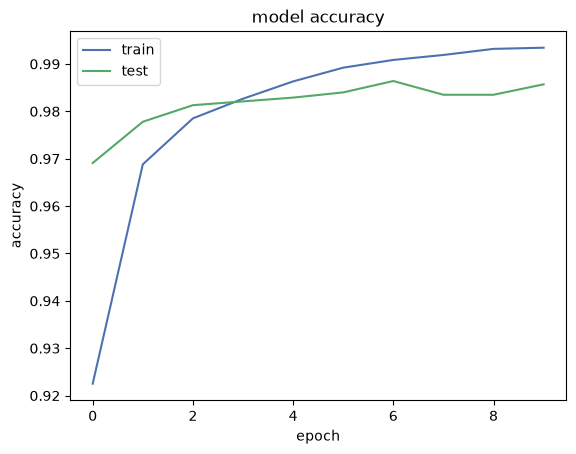

In [29]:
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()

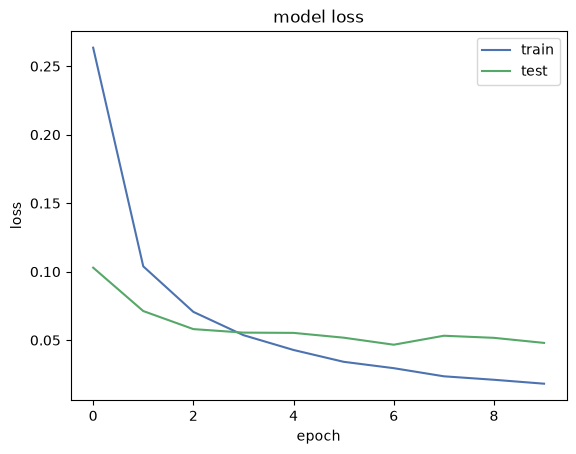

In [30]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()

In [31]:
print(y_test[1])
print(type(y_test[1]))
print(y_test.shape)

2
<class 'numpy.uint8'>
(10000,)


In [32]:
y_predict_single = np.argmax(model.predict(x_test[[1]]), axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


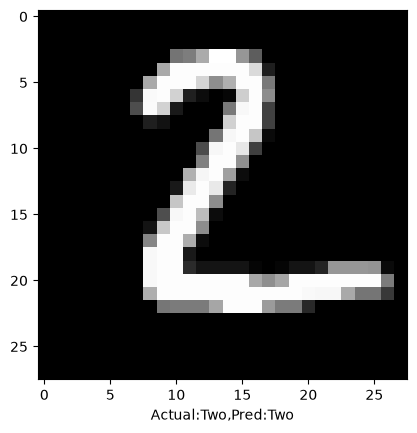

In [33]:
#Names of numbers in the dataset in order
col_names = ['Zero','One','Two','Three','Four','Five','Six','Seven','Eight','Nine']

#Visualizing the digits
#plt.figure(figsize=(10,10))
plt.imshow(x_test[1].reshape(28,28), cmap='gray')
plt.xlabel("Actual:{},Pred:{}".format(col_names[int(y_test[1])],col_names[y_predict_single[0]]))
plt.show()